In [2]:
import kagglehub

path = kagglehub.dataset_download(
    "abdallahalidev/plantvillage-dataset"
)

print(path)


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
/kaggle/input/plantvillage-dataset


In [3]:
selected_classes = [
    "Apple___Apple_scab",
    "Apple___healthy",
    "Potato___Early_blight",
    "Potato___healthy",
    "Tomato___Tomato_mosaic_virus"
]

print(selected_classes)

['Apple___Apple_scab', 'Apple___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato___Tomato_mosaic_virus']


In [4]:
from pathlib import Path

data_dir = Path(path) / "plantvillage dataset" / "color"

print(data_dir)

/kaggle/input/plantvillage-dataset/plantvillage dataset/color


In [5]:
for class_name in selected_classes:
    class_dir = data_dir / class_name
    images = list(class_dir.glob("*"))
    print(class_name, ":", len(images), "images")

Apple___Apple_scab : 630 images
Apple___healthy : 1645 images
Potato___Early_blight : 1000 images
Potato___healthy : 152 images
Tomato___Tomato_mosaic_virus : 373 images


In [6]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import models
import matplotlib.pyplot as plt

In [7]:
img_height = 180
img_width = 180
batch_size = 32

train_ds=tf.keras.utils.image_dataset_from_directory(
    data_dir,
    class_names=selected_classes,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height,img_width),
    batch_size=batch_size
)

val_ds=tf.keras.utils.image_dataset_from_directory(
    data_dir,
    class_names=selected_classes,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height,img_width),
    batch_size=batch_size
    )

Found 3800 files belonging to 5 classes.
Using 3040 files for training.
Found 3800 files belonging to 5 classes.
Using 760 files for validation.


['Apple___Apple_scab', 'Apple___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato___Tomato_mosaic_virus']


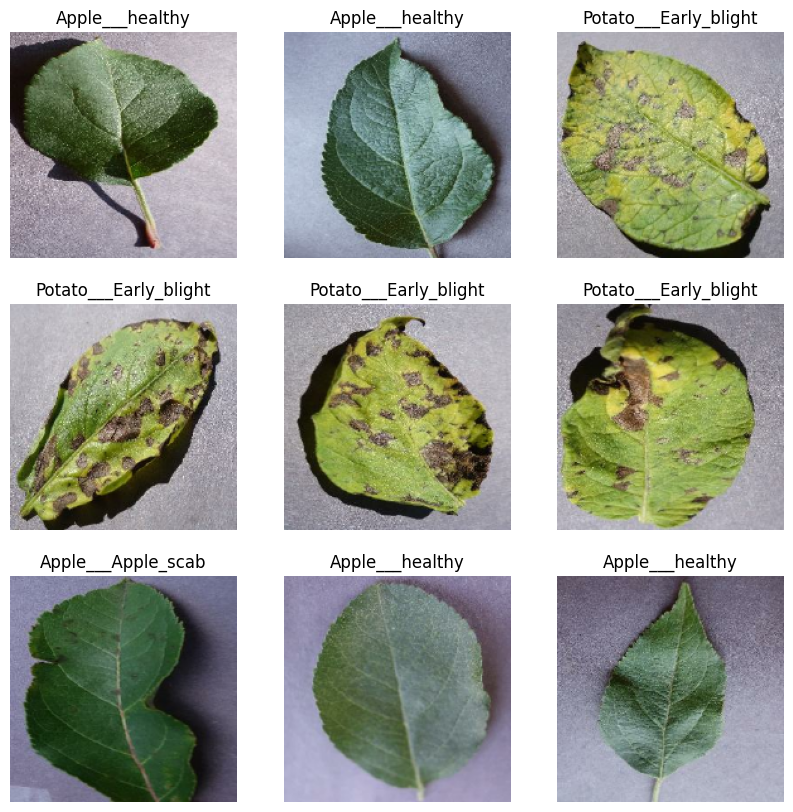

In [8]:
class_names = train_ds.class_names
print(class_names)
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

In [10]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

/tmp/ipykernel_622/2044152240.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [11]:

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(5)
])

In [12]:
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
epochs_range=10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs_range
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 32s 117ms/step - accuracy: 0.7859 - loss: 0.5574 - val_accuracy: 0.9013 - val_loss: 0.3128
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8954 - loss: 0.2940 - val_accuracy: 0.9013 - val_loss: 0.2664
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9293 - loss: 0.2065 - val_accuracy: 0.9013 - val_loss: 0.2686
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9418 - loss: 0.1701 - val_accuracy: 0.9026 - val_loss: 0.2464
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9533 - loss: 0.1392 - val_accuracy: 0.9342 - val_loss: 0.1727
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9530 - loss: 0.1323 - val_accuracy: 0.9461 - val_loss: 0.1534
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9697 - loss: 0.1008 - val_accuracy: 0.9474 - val_loss: 0.1529
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9714 - loss: 0.0880 - val_accuracy: 0.9289 -

In [15]:
test_loss, test_accuracy = model.evaluate(val_ds)

print("Validation Loss:", test_loss)
print("Validation Accuracy:", test_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9329 - loss: 0.1916
Validation Loss: 0.1915683001279831
Validation Accuracy: 0.932894766330719


In [16]:
epochs_range = range(len(history.history["accuracy"]))
accuracy = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

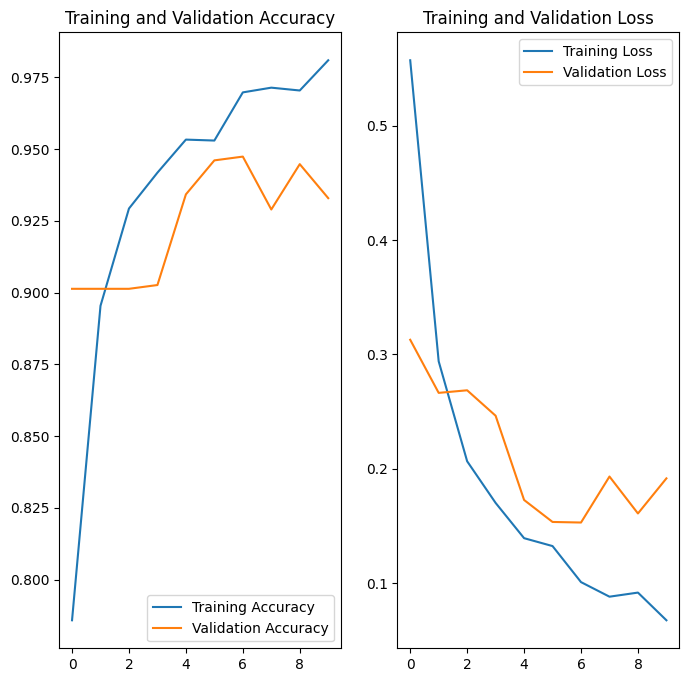

In [17]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [18]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9329 - loss: 0.1916
Validation Loss: 0.1915683001279831
Validation Accuracy: 0.932894766330719


In [19]:
best_val_accuracy = max(history.history["val_accuracy"])

print("Best Validation Accuracy:", best_val_accuracy)

Best Validation Accuracy: 0.9473684430122375


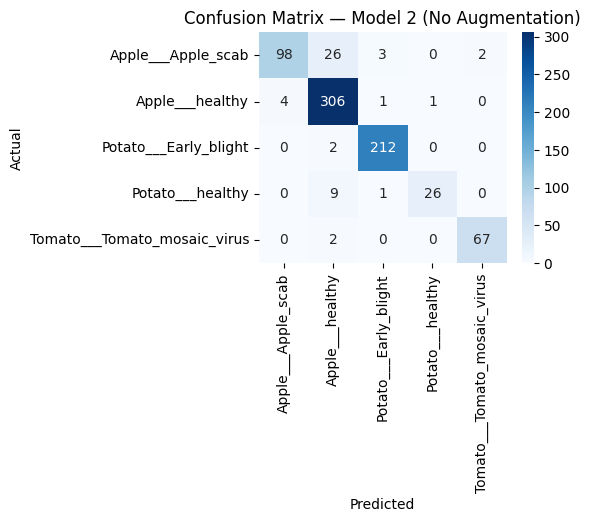

                              precision    recall  f1-score   support

          Apple___Apple_scab       0.96      0.76      0.85       129
             Apple___healthy       0.89      0.98      0.93       312
       Potato___Early_blight       0.98      0.99      0.98       214
            Potato___healthy       0.96      0.72      0.83        36
Tomato___Tomato_mosaic_virus       0.97      0.97      0.97        69

                    accuracy                           0.93       760
                   macro avg       0.95      0.88      0.91       760
                weighted avg       0.94      0.93      0.93       760



In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np
y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true, y_pred = np.array(y_true), np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Model 2 (No Augmentation)')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

In [21]:
from google.colab import files

uploaded = files.upload()

Saving test image.jpg to test image.jpg


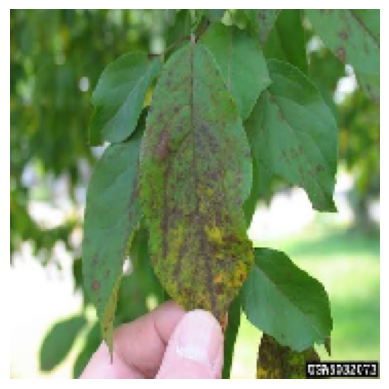

In [22]:
test_image_path = "test image.jpg"

img = tf.keras.utils.load_img(
    test_image_path,
    target_size=(img_height, img_width)
)

plt.imshow(img)
plt.axis("off")
plt.show()

In [23]:
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array)

score = tf.nn.softmax(predictions[0])

predicted_class = class_names[np.argmax(score)]
confidence = 100 * np.max(score)

print("Predicted class:", predicted_class)
print("Confidence:", confidence, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Predicted class: Apple___Apple_scab
Confidence: 94.85464 %


# Fine tuning

In [23]:
base_model.trainable = True
print("Total layers:", len(base_model.layers))

Total layers: 154


In [24]:
for layer in base_model.layers[:-20]:
    layer.trainable = False

In [25]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

In [32]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.7954 - loss: 1.0145 - val_accuracy: 0.9355 - val_loss: 0.2155
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.8803 - loss: 0.4095 - val_accuracy: 0.9289 - val_loss: 0.2317
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9260 - loss: 0.2237 - val_accuracy: 0.9289 - val_loss: 0.2398
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9595 - loss: 0.1361 - val_accuracy: 0.9250 - val_loss: 0.2403
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9766 - loss: 0.0895 - val_accuracy: 0.9263 - val_loss: 0.2438
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9865 - loss: 0.0601 - val_accuracy: 0.9184 - val_loss: 0.2447
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9924 - loss: 0.0417 - val_accuracy: 0.9197 - val_loss: 0.2482
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9967 - loss: 0.0301 - val_accuracy: 0.9211 - v

In [33]:
fine_loss, fine_accuracy = model.evaluate(val_ds)

print("Fine-tuned Validation Loss:", fine_loss)
print("Fine-tuned Validation Accuracy:", fine_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9184 - loss: 0.2520
Fine-tuned Validation Loss: 0.2520439326763153
Fine-tuned Validation Accuracy: 0.9184210300445557


In [34]:
best_fine_accuracy = max(
    fine_tune_history.history["val_accuracy"]
)

print("Best Fine-tuned Validation Accuracy:", best_fine_accuracy)

Best Fine-tuned Validation Accuracy: 0.9355263113975525


fine tuning gives worst result so we will not be doing this

In [24]:
import numpy as np
from sklearn.metrics import classification_report
val_loss,val_acc=model.evaluate(val_ds)

y_true,y_pred=[],[]
for image,label in val_ds:
  preds=model.predict(image,verbose=0)
  y_true.extend(label.numpy())
  y_pred.extend(np.argmax(preds,axis=1))

report = classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)
print(report)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9329 - loss: 0.1916
{'Apple___Apple_scab': {'precision': 0.9607843137254902, 'recall': 0.7596899224806202, 'f1-score': 0.8484848484848485, 'support': 129.0}, 'Apple___healthy': {'precision': 0.8869565217391304, 'recall': 0.9807692307692307, 'f1-score': 0.9315068493150684, 'support': 312.0}, 'Potato___Early_blight': {'precision': 0.9769585253456221, 'recall': 0.9906542056074766, 'f1-score': 0.9837587006960556, 'support': 214.0}, 'Potato___healthy': {'precision': 0.9629629629629629, 'recall': 0.7222222222222222, 'f1-score': 0.8253968253968254, 'support': 36.0}, 'Tomato___Tomato_mosaic_virus': {'precision': 0.9710144927536232, 'recall': 0.9710144927536232, 'f1-score': 0.9710144927536232, 'support': 69.0}, 'accuracy': 0.9328947368421052, 'macro avg': {'precision': 0.9517353633053658, 'recall': 0.8848700147666346, 'f1-score': 0.9120323433292843, 'support': 760.0}, 'weighted avg': {'precision': 0.9360623715050351, 'recall': 0.932894736842

In [25]:
import pandas as pd
result=pd.DataFrame([{
    "Model": "MobileNetV2 (frozen)",
    "Val acc":val_acc,
    "Val loss":val_loss,
    "Best val acc":best_val_accuracy,
    "Macro F1": report["macro avg"]["f1-score"],
}])

In [26]:
result.to_csv("mobilenet_frozen_results.csv", index=False)
print(result)

                  Model   Val acc  Val loss  Best val acc  Macro F1
0  MobileNetV2 (frozen)  0.932895  0.191568      0.947368  0.912032
